In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"

# elif "augustiner" in hostname: 
#     DATA_DIR = "/home/franzihe/Data/"
#     FIG_DIR = "/home/franzihe/Documents/Figures/mrr_reflectivity/"

if "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)
# sys.path.append(os.path.join(UTILS_DIR, 'pymascdb'))
os.chdir(os.path.join(UTILS_DIR, 'pymascdb'))

# # make figure directory to put in reflectivity processed data
# try:
#     new_dir = pathlib.Path(FIG_DIR)
#     new_dir.mkdir(parents=True, exist_ok=True)
# except OSError:
#     pass

mimi.uio.no


In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

In [3]:
from imports_mascdb import (masc, np, pd, cm, xr, glob, set_context, plt, mdates, time, datetime)

In [4]:
# from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, ListedColormap
# import seaborn as sns
# from matplotlib.patches import Patch

import functions_mascdb as fct

In [5]:
# reload imports
%load_ext autoreload
%autoreload 2

In [6]:
set_context('paper', font_scale=1.5, rc={"lines.linewidth": 2})

In [7]:
masc_in = os.path.join(INPUT_DATA_DIR, 'MASC_DB')

In [8]:
### Create MASC_DB instance 
mascdb = masc.MASC_DB(dir_path=masc_in)

In [9]:
mascdb.campaign

,start_time,end_time,latitude,longitude,altitude,n_triplets,n_events,event_duration_min,event_duration_mean,event_duration_max,total_event_duration,snowflake_class,riming_class,melting_class,precipitation_class
campaign,,,,,,,,,,,,,,,
ISLAS-2022,2022-03-29 08:51:20.012828,2022-04-02 19:27:26.029542,69.2985,16.0481,10.0,3407,7,0 days,0 days 12:38:16.885321571,1 days 17:10:40.043786,3 days 16:27:58.197251,"{'graupel': 2140, 'aggregate': 828, 'small_par...","{'graupel': 2602, 'rimed': 474, 'densely_rimed...","{'dry': 3395, 'melting': 12}","{'mixed': 1966, 'precip': 1395, 'blowing_snow'..."
Norway-2016,2016-10-14 03:00:16.635184,2016-12-25 12:16:31.745234,59.8118,7.2143,991.0,45927,72,0 days,0 days 04:37:51.772570013,3 days 20:48:05.496422,13 days 21:26:07.625041,"{'graupel': 20434, 'small_particle': 16050, 'a...","{'graupel': 30130, 'rimed': 10076, 'densely_ri...","{'dry': 45403, 'melting': 524}","{'mixed': 21208, 'precip': 18453, 'blowing_sno..."
Norway-2023,2023-02-19 08:20:20.575449,2023-03-13 12:45:20.357433,69.2954,16.0337,13.0,17217,29,0 days,0 days 09:08:23.377584068,2 days 15:21:39.590326,11 days 01:03:17.949938,"{'graupel': 11692, 'aggregate': 4518, 'small_p...","{'graupel': 14312, 'rimed': 1424, 'densely_rim...","{'dry': 17124, 'melting': 93}","{'mixed': 10194, 'precip': 6778, 'blowing_snow..."


In [10]:
campaign = 'Norway-2023'
# campaign = 'ISLAS-2022'

In [11]:
# campaign23 = mascdb.select_campaign('Norway-2023')
campaign23 = mascdb.select_campaign(campaign)


In [12]:
campaign23.campaign

,start_time,end_time,latitude,longitude,altitude,n_triplets,n_events,event_duration_min,event_duration_mean,event_duration_max,total_event_duration,snowflake_class,riming_class,melting_class,precipitation_class
campaign,,,,,,,,,,,,,,,
Norway-2023,2023-02-19 08:20:20.575449,2023-03-13 12:45:20.357433,69.2954,16.0337,13.0,17217,29,0 days,0 days 09:08:23.377584068,2 days 15:21:39.590326,11 days 01:03:17.949938,"{'graupel': 11692, 'aggregate': 4518, 'small_p...","{'graupel': 14312, 'rimed': 1424, 'densely_rim...","{'dry': 17124, 'melting': 93}","{'mixed': 10194, 'precip': 6778, 'blowing_snow..."


In [13]:
# campaign23.campaign.loc['Norway-2023']
campaign23.campaign.loc[campaign]


start_time                                     2023-02-19 08:20:20.575449
end_time                                       2023-03-13 12:45:20.357433
latitude                                                          69.2954
longitude                                                         16.0337
altitude                                                             13.0
n_triplets                                                          17217
n_events                                                               29
event_duration_min                                        0 days 00:00:00
event_duration_mean                             0 days 09:08:23.377584068
event_duration_max                                 2 days 15:21:39.590326
total_event_duration                              11 days 01:03:17.949938
snowflake_class         {'graupel': 11692, 'aggregate': 4518, 'small_p...
riming_class            {'graupel': 14312, 'rimed': 1424, 'densely_rim...
melting_class                         

In [14]:
# campaign23.campaign.loc['Norway-2023']['snowflake_class']
campaign23.campaign.loc[campaign]['snowflake_class']


{'graupel': 11692,
 'aggregate': 4518,
 'small_particle': 706,
 'planar_crystal': 250,
 'columnar_crystal': 40,
 'columnar_planar_combination': 11}

In [15]:
# campaign23.campaign.loc['Norway-2023']['riming_class']
campaign23.campaign.loc[campaign]['riming_class']


{'graupel': 14312,
 'rimed': 1424,
 'densely_rimed': 1370,
 'undefined': 93,
 'graupel-like': 14,
 'unrimed': 4}

In [16]:
# campaign23.campaign.loc['Norway-2023']['precipitation_class']
campaign23.campaign.loc[campaign]['precipitation_class']


{'mixed': 10194, 'precip': 6778, 'blowing_snow': 237, 'undefined': 8}

In [17]:
campaign23.campaign.loc[campaign]

start_time                                     2023-02-19 08:20:20.575449
end_time                                       2023-03-13 12:45:20.357433
latitude                                                          69.2954
longitude                                                         16.0337
altitude                                                             13.0
n_triplets                                                          17217
n_events                                                               29
event_duration_min                                        0 days 00:00:00
event_duration_mean                             0 days 09:08:23.377584068
event_duration_max                                 2 days 15:21:39.590326
total_event_duration                              11 days 01:03:17.949938
snowflake_class         {'graupel': 11692, 'aggregate': 4518, 'small_p...
riming_class            {'graupel': 14312, 'rimed': 1424, 'densely_rim...
melting_class                         

In [18]:
snowflake_class = {'graupel': campaign23.select_snowflake_class('graupel'), 
                   'aggregate': campaign23.select_snowflake_class('aggregate'), 
                   'small_particle': campaign23.select_snowflake_class('small_particle'), 
                   'planar_crystal': campaign23.select_snowflake_class('planar_crystal'), 
                   'columnar_crystal': campaign23.select_snowflake_class('columnar_crystal'), 
                   'columnar_planar_combination': campaign23.select_snowflake_class('columnar_planar_combination')}

In [19]:
# Choose a colormap from cmcrameri (e.g., 'batlow', 'lajolla', etc.)
cmap = cm.lipari

# Manually define colors from the colormap for each snowflake characteristic
# You can either define them manually or map them from the colormap
# colors = [cmap(0.1), cmap(0.3), cmap(0.5), cmap(0.7)]  # Assigning colors from the colormap

# Generate 6 evenly spaced values between 0 and 1
color_positions = np.linspace(0, 1, 6)

# Map each value to a color in the colormap
colors = [cmap(pos) for pos in color_positions]


In [20]:
# Example start and end date for xlim (modify these as needed)
start_date = pd.to_datetime(campaign23.triplet.datetime.min().date())
end_date = pd.to_datetime(campaign23.triplet.datetime.max().date())

In [21]:
markers = ['o', '^', '*', 'h', 's', 'd']

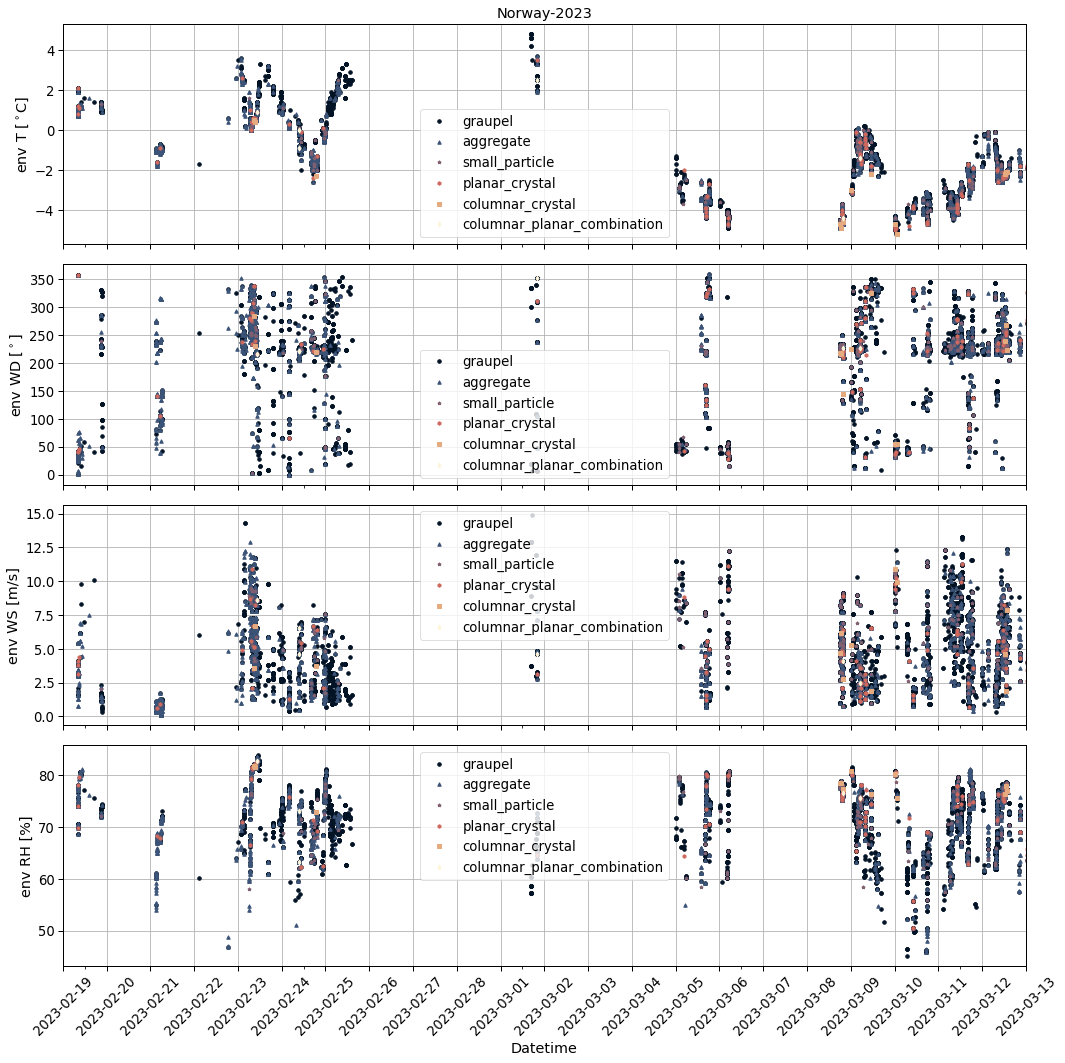

In [22]:
# Create a figure and axis object
fig, axsm = plt.subplots(4,1,figsize=(15, 15), sharex=True)
axs = axsm.flatten()


for (class_name, da), marker, color in zip(snowflake_class.items(), markers,colors):
    # Plot temperature of characteristics on the same axes
    snowflake_class[class_name].triplet.plot(x='datetime', y='env_T', marker=marker, label=class_name, linestyle='None', ax=axs[0], color=color, markersize=3.5)
    # Plot wind direction of characteristics on the same axes
    snowflake_class[class_name].triplet.plot(x='datetime', y='env_DD', marker=marker, label=class_name, linestyle='None', ax=axs[1], color=color, markersize=3.5)
    
    # Plot wind speed of characteristics on the same axes
    snowflake_class[class_name].triplet.plot(x='datetime', y='env_FF', marker=marker, label=class_name, linestyle='None', ax=axs[2], color=color, markersize=3.5)
    
    # Plot relative humidity of characteristics on the same axes
    snowflake_class[class_name].triplet.plot(x='datetime', y='env_RH', marker=marker, label=class_name, linestyle='None', ax=axs[3], color=color, markersize=3.5)


axs[0].set_ylabel('env T [$^\circ$C]')
axs[1].set_ylabel('env WD [$^\circ$]')
axs[2].set_ylabel('env WS [m/s]')
axs[3].set_ylabel('env RH [%]')


    
# Set the x-axis labels daily using DateFormatter and DayLocator
for ax in axs:
    ax.legend()
    ax.grid(True)
    
    ax.set_xlim([start_date, end_date])  # Set xlim to specific date range
    ax.xaxis.set_major_locator(mdates.DayLocator())  # Set ticks for every day
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # Format labels as dates (Year-Month-Day)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="center")  # Rotate the labels for better readability


axs[3].set_xlabel('Datetime')
axs[0].set_title(campaign)


plt.tight_layout()
# Show the plot
plt.show()


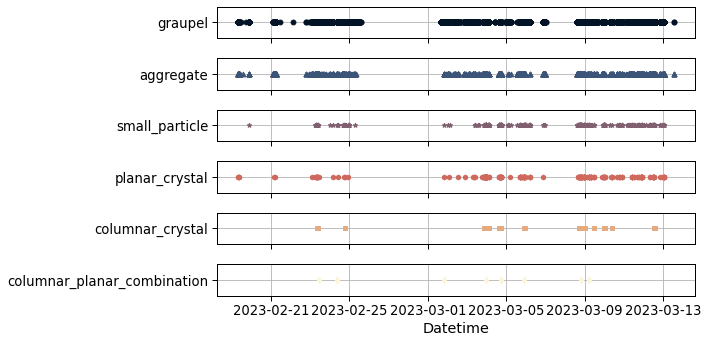

In [23]:
fig, axsm = plt.subplots(6,1,figsize=(10, 5), sharex=True)
axs = axsm.flatten()
y_level = 1


for (class_name, da), marker, color, ax in zip(snowflake_class.items(), markers,colors,axs):
    # Plot temperature of characteristics on the same axes
    ax.plot(snowflake_class[class_name].triplet.datetime, [y_level]*snowflake_class[class_name].triplet.datetime.size, marker=marker, label=class_name, color=color, linestyle='None')
    
    ax.set_yticks([y_level])  # optional: label y-axis
    ax.set_yticklabels([class_name])
    ax.grid(True)

    
# Formatting
ax.set_xlabel('Datetime')
fig.tight_layout()
plt.show()

In [24]:
for (class_name, da) in (snowflake_class.items()):
    df = snowflake_class[class_name].triplet
    
    # Set the 'datetime' column as the index and the current index becomes a column and rename to 'time'
    df.set_index('datetime', inplace=True)
    df.index = df.index.rename('time')

    # Convert the pandas DataFrame to xarray Dataset
    ds = xr.Dataset.from_dataframe(df)

    # Save to a NetCDF file
    # ds.to_netcdf(os.path.join(INPUT_DATA_DIR,f'MASC_DB/{campaign}_{class_name}.nc'))


In [25]:
# how many times graupel (or any particle type) was recorded in each 5-minute interval

In [26]:
df = campaign23.triplet
df.set_index('datetime', inplace=True)
df.index = df.index.rename('time')

In [27]:
# Get the current Unix timestamp
current_timestamp = time.time()
# Convert the epoch time to a datetime object in UTC
utc_datetime = datetime.utcfromtimestamp(current_timestamp)

# Format the datetime object into the desired string format
formatted_utc_time = utc_datetime.strftime("%Y-%m-%d %H:%M")

In [28]:
df_2 = df[['snowflake_class_name', 'riming_deg_level', 'bs_precip_class_name', 'flake_Dmax', ]]
dataset = df_2.to_xarray()#
dataset = dataset.assign_attrs(title = 'Snowfall habits processed with MASCDB',
                     institution='Dept. of Geoscience, University of Oslo',
                     contact_person='F. Hellmuth',
                     source='MASC',
                     location='Andenes',
                     history='Created with MASCDB',
                     created_date=f'{formatted_utc_time} UTC',
                     reference='Grazioli, J., Ghiggi, G., Billault-Roux, AC. et al. MASCDB, a database of images, descriptors and microphysical properties of individual snowflakes in free fall. Sci Data 9, 186 (2022). https://doi.org/10.1038/s41597-022-01269-7')
# dataset.to_netcdf(os.path.join(INPUT_DATA_DIR,f'MASC_DB/{campaign}_MASCDB_habits.nc'))

In [29]:
df.columns

Index(['campaign', 'latitude', 'longitude', 'altitude', 'flake_id',
       'flake_number_tmp', 'flake_quality_xhi', 'fallspeed', 'flake_n_roi',
       'flake_Dmax', 'riming_deg_level', 'riming_class_id',
       'riming_class_prob', 'riming_class_name', 'melting_class_id',
       'melting_prob', 'melting_class_name', 'snowflake_class_name',
       'snowflake_class_id', 'snowflake_class_prob', 'gan3d_mass',
       'gan3d_volume', 'gan3d_gyration', 'env_T', 'env_P', 'env_DD', 'env_FF',
       'env_RH', 'bs_normalized_angle', 'bs_mixing_ind',
       'bs_precip_class_name', 'bs_precip_class_id', 'event_id',
       'event_duration', 'event_n_triplets'],
      dtype='object')

In [30]:
(df.loc[df['snowflake_class_name'] == 'planar_crystal', 'snowflake_class_name']).count()

250

In [31]:
df.loc[df['snowflake_class_name'] == 'small_particle', 'snowflake_class_name'] = 'pristine'
df.loc[df['snowflake_class_name'] == 'planar_crystal', 'snowflake_class_name'] = 'pristine'
df.loc[df['snowflake_class_name'] == 'columnar_crystal', 'snowflake_class_name'] = 'pristine'
df.loc[df['snowflake_class_name'] == 'columnar_planar_combination', 'snowflake_class_name'] = 'pristine'

In [32]:
df.groupby([pd.Grouper(freq='1min'), 'snowflake_class_name']).size().unstack(fill_value=0)

snowflake_class_name,aggregate,graupel,pristine
time,,,
2023-02-19 08:20:00,3,4,1
2023-02-19 08:21:00,4,2,0
2023-02-19 08:22:00,4,5,0
2023-02-19 08:23:00,0,6,0
2023-02-19 08:24:00,4,5,1
...,...,...,...
2023-03-13 01:26:00,2,1,0
2023-03-13 01:27:00,2,1,0
2023-03-13 01:31:00,0,1,0


In [33]:
df

,campaign,latitude,longitude,altitude,flake_id,flake_number_tmp,flake_quality_xhi,fallspeed,flake_n_roi,flake_Dmax,...,env_DD,env_FF,env_RH,bs_normalized_angle,bs_mixing_ind,bs_precip_class_name,bs_precip_class_id,event_id,event_duration,event_n_triplets
time,,,,,,,,,,,,,,,,,,,,,
2023-02-19 08:20:20.575449,Norway-2023,69.2954,16.0337,13.0,2023.02.19_08.20.20_flake_6,6,8.4,0.102,8.0,0.00375,...,43.0,3.8,68.7,0.103,NaN,precip,1,79,0 days 13:09:26.899738,197
2023-02-19 08:20:23.570655,Norway-2023,69.2954,16.0337,13.0,2023.02.19_08.20.23_flake_7,7,9.4,0.197,5.0,0.00956,...,43.0,3.8,68.7,0.061,NaN,precip,1,79,0 days 13:09:26.899738,197
2023-02-19 08:20:24.101058,Norway-2023,69.2954,16.0337,13.0,2023.02.19_08.20.24_flake_8,8,8.1,2.373,5.0,0.00323,...,43.0,3.8,68.7,0.059,NaN,precip,1,79,0 days 13:09:26.899738,197
2023-02-19 08:20:25.068263,Norway-2023,69.2954,16.0337,13.0,2023.02.19_08.20.25_flake_9,9,9.2,1.417,8.0,0.00265,...,43.0,3.8,68.7,0.062,NaN,precip,1,79,0 days 13:09:26.899738,197
2023-02-19 08:20:32.088271,Norway-2023,69.2954,16.0337,13.0,2023.02.19_08.20.32_flake_11,11,9.6,2.127,7.0,0.00955,...,43.0,3.8,69.7,0.048,NaN,precip,1,79,0 days 13:09:26.899738,197
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-03-13 12:45:11.387416,Norway-2023,69.2954,16.0337,13.0,2023.03.13_12.45.11_flake_47735,47735,8.5,1.790,6.0,0.00298,...,285.0,1.5,47.9,0.444,0.41,mixed,2,107,0 days 00:00:08.970017,5
2023-03-13 12:45:12.682218,Norway-2023,69.2954,16.0337,13.0,2023.03.13_12.45.12_flake_47736,47736,9.3,2.101,19.0,0.00725,...,285.0,1.5,47.9,0.246,0.09,mixed,2,107,0 days 00:00:08.970017,5
2023-03-13 12:45:17.237424,Norway-2023,69.2954,16.0337,13.0,2023.03.13_12.45.17_flake_47740,47740,8.8,2.152,26.0,0.00610,...,285.0,1.5,47.9,0.779,0.87,mixed,2,107,0 days 00:00:08.970017,5


In [34]:
# Limit the fallspeed
# df['fallspeed'][df['fallspeed'] > 7.] = np.nan
# df['fallspeed'][df['fallspeed'] <= 0.2] = np.nan

In [35]:
# dataset = df.to_xarray()#
# dataset = dataset.assign_attrs(title = 'Snowfall habits processed with MASCDB',
#                      institution='Dept. of Geoscience, University of Oslo',
#                      contact_person='F. Hellmuth',
#                      source='MASC',
#                      location='Andenes',
#                      history='Created with MASCDB',
#                      created_date=f'{formatted_utc_time} UTC',
#                      reference='Grazioli, J., Ghiggi, G., Billault-Roux, AC. et al. MASCDB, a database of images, descriptors and microphysical properties of individual snowflakes in free fall. Sci Data 9, 186 (2022). https://doi.org/10.1038/s41597-022-01269-7')
# dataset.to_netcdf(os.path.join(INPUT_DATA_DIR,f'MASC_DB/{campaign}_MASCDB_aggregate_graupel_pristine.nc'))

In [36]:

# Combine HATPRO 10 min averaged temperature and Airport 10 min wind data
ds = xr.open_mfdataset(sorted(glob(os.path.join(INPUT_DATA_DIR, 'Met-No_obs/SN87110', 'ANX_wind_10min_to_1min_filled_2023.nc'))))
# substitute the wind direction and speed and remove the variable *_filled*
ds['wind_direction'] = ds['wind_direction_filled'].copy()
ds['wind_speed'] = ds['wind_speed_filled'].copy()
# ds = ds.drop_vars(["wind_direction_filled", "wind_speed_filled"],)

ds_t  = xr.open_mfdataset(sorted(glob(os.path.join(INPUT_DATA_DIR, f'hatpro/hatpro_new_20240716/level1/2023/*/*/*.nc'))))


In [37]:
# 1) turn the xarray DataArray into a pandas Series (index = minute grid)
wind_dir = ds['wind_direction'].to_series()      # dtype: float64, index = DatetimeIndex
wind_spd = ds['wind_speed'].to_series()
temp = ds_t['air_temperature'].to_series()

In [38]:
# 2) align the Series to the irregular DataFrame index, picking the nearest minute
#    (tolerance keeps “orphan” rows from getting a value that is >30 s away)
df['env_DD_test'] = wind_dir.reindex(df.index, method='nearest',
                                tolerance=pd.Timedelta('30s'))
df['env_FF_test'] = wind_spd.reindex(df.index, method='nearest',
                                tolerance=pd.Timedelta('30s'))
df['env_T_test'] = temp.reindex(df.index, method ='nearest', tolerance=pd.Timedelta('30s'))

In [39]:
df_orig = df[['env_T_test', 'env_DD_test', 'env_FF_test', 'snowflake_class_name', 'riming_deg_level']]

In [40]:
df_orig['env_T_test'] = df_orig['env_T_test'] - 273.15

In [41]:
# # Define Wind direction bins into 8 wind direction sectors
# direction_labels_8=['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
# df_env_nan = fct.get_wind_sectors(df_env_nan, direction_labels=direction_labels_8, )

# # Define Wind direction bins into 16 compass sectors
# direction_labels_16 = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE', 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW',]
# df_env_nan = fct.get_wind_sectors(df_env_nan, direction_labels=direction_labels_16, col_out_name='compass')

In [42]:
# # make figure directory to put in 
# try:
#     new_dir = pathlib.Path(FIG_DIR+'sf_class_frequ/orig/')
#     new_dir.mkdir(parents=True, exist_ok=True)
# except OSError:
#     pass

In [43]:
# # Normalized frequencies
# fct.plt_snowflake_heatmap_by_sector(df_env_nan, mode="percent", title="Relative Frequency of Snowflake Classes by Wind Sector", )

# figname = f"sf_class_frequ/orig/relative_sf_class_frequency_by_wind_sector.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [44]:
# # Absolute counts
# fct.plt_snowflake_heatmap_by_sector(df_env_nan, mode="absolute", title="Absolute Count of Snowflake Classes by Wind Sector", data_max=2500)

# figname = f"sf_class_frequ/orig/absolute_count_sf_class_frequency_by_wind_sector.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [45]:
# # Graupel to Aggregate ratio
# fct.plt_snowflake_heatmap_by_sector(df_env_nan, mode="ratio", class_ratio=("graupel", "aggregate"), title = "Graupel-to-Aggregate Ratio by Wind Sector", figsize=(10, 2), data_max=6.5)

# figname = f"sf_class_frequ/orig/graupel_to_aggregate_ratio_by_wind_sector.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

#### Colorize bins by dominant class 
Which snowflake class is most frequent in each wind sector?

In [46]:
# #Group counts Compute Snowflake Frequencies per ( Wind Sector)
# counts = df_env_nan.groupby(['wind_direction_sector', 'snowflake_class_name']).size().reset_index(name='count')
# # Pivot to a contingency table: rows=(temp, wind), columns=snowflake_class
# pivot_table = counts.pivot_table(index=['wind_direction_sector'], columns='snowflake_class_name', values='count', fill_value=0)

In [47]:
# # Define colors for classes
# custom_colors = {
#                  'aggregate': cm.davos(0.),
#                  'graupel':cm.davos(0.33),
#                  'pristine':cm.davos(0.89),                 
#                 }
# fct.plt_dominant_snowflake_class_by_sector(pivot_table, class_colors=custom_colors)
# figname = f"sf_class_frequ/orig/bar_dominant_sf_class_by_wind_sector.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [48]:
# fct.plt_dominant_snowflake_class_heatmap(pivot_table, class_colors=custom_colors)
# figname = f"sf_class_frequ/orig/heatmap_dominant_sf_class_by_wind_sector.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [49]:
# # Normalize within each direction
# fct.plt_stacked_snowflake_windrose(df_env_nan, direction_labels=direction_labels_8, class_color=custom_colors, title="Snowflake Types by Wind Sector - Normalized by Wind Sector", mode="per_direction")

# fct.plt_stacked_snowflake_windrose(df_env_nan, direction_labels=direction_labels_16, class_color=custom_colors, title="Snowflake Types by Wind Sector - Normalized", mode="per_direction")

In [50]:
# # raw counts
# # fct.plt_stacked_snowflake_windrose(df_env_nan, direction_labels=['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'], class_color=custom_colors, title="Snowflake Types by Wind Sector", mode="count")

# fct.plt_stacked_snowflake_windrose(df_env_nan, direction_labels=direction_labels_16, class_color=custom_colors, title="Snowflake Types by Wind Sector", mode="count")
# figname = f"sf_class_frequ/orig/windrose_sf_class_by_wind_sector_count.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [51]:
# # Normalize total normalized % version
# fct.plt_stacked_snowflake_windrose(df_env_nan, direction_labels=direction_labels_8, class_color=custom_colors, title="Snowflake Types by Wind sector - Normalized Globally", mode="total")

# fct.plt_stacked_snowflake_windrose(df_env_nan, direction_labels=direction_labels_16, class_color=custom_colors, title="Snowflake Types by Wind sector - Normalized", mode="total")
# figname = f"sf_class_frequ/orig/windrose_sf_class_by_wind_sector_normalized_total.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)


#### Test dominance threshold
Snowflake class with no threshold, >50%, >70% and 1'/10'/30' binning

In [52]:
df_orig["env_T_1h"] = df_orig['env_T_test'].resample("1H").transform("mean")

(-6.0, 5.0)

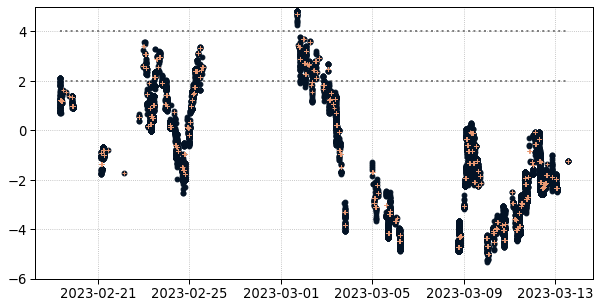

In [53]:
temp = (df_orig['env_T_test'])
temp_mean = (df_orig["env_T_1h"])

fig, ax = plt.subplots(figsize=(10,5))
ax.grid(True, ls=':')
ax.plot(temp, linestyle="", marker="o", color=cm.lipariS(0))
ax.plot(temp_mean, linestyle ="", marker="+", color=cm.lipariS(3))
ax.hlines(y=4., xmin=temp.index[0], xmax=temp.index[-1], colors='gray', linestyles=":")
ax.hlines(y=2., xmin=temp.index[0], xmax=temp.index[-1], colors='gray', linestyles=":")

ax.set_ylim([-6, 5])

In [54]:
# only use rows where the temperature is below 4C (most likely only on March first 16 to 17UTC)
# df_t_thresh = df_orig.loc[df_orig["env_T_1h"] <4.]

df_t_thresh = df_orig.loc[df_orig["env_T_test"] <=2.]

In [55]:
df_env = dict()

posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


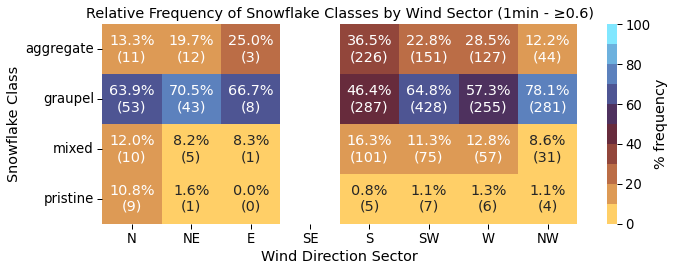

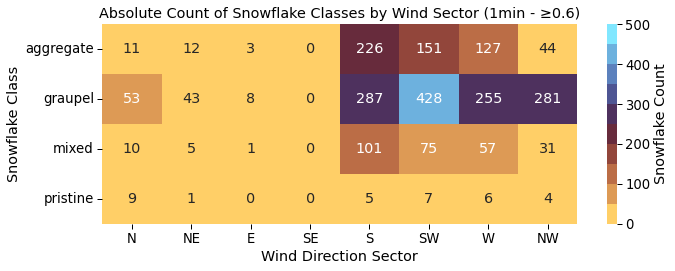

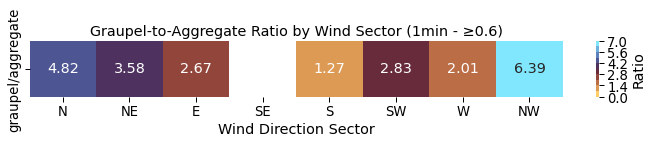

posx and posy should be finite values
posx and posy should be finite values


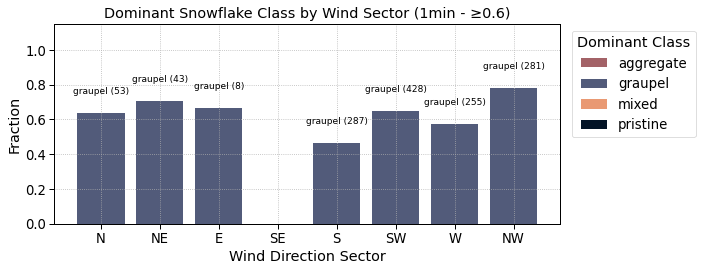

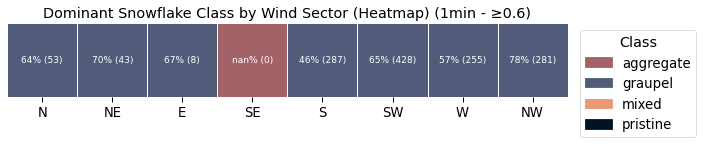

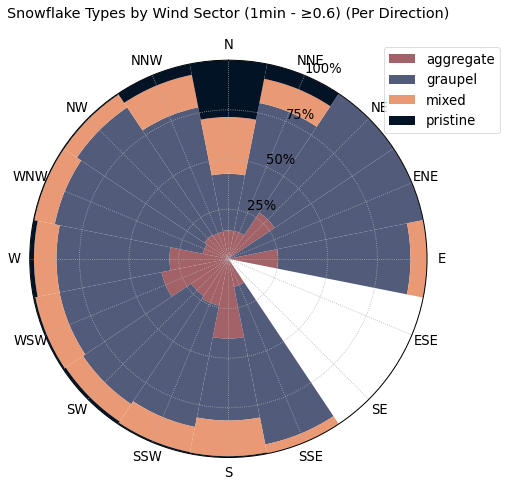

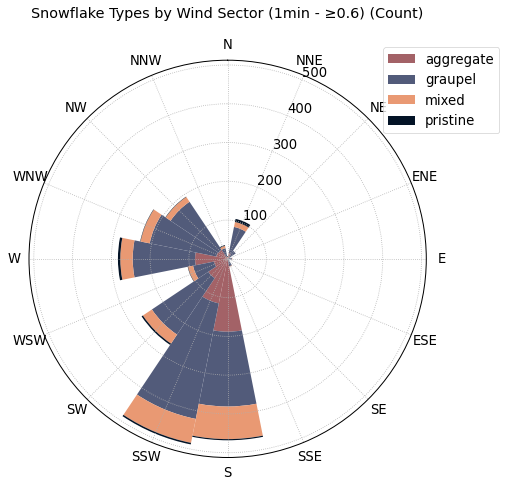

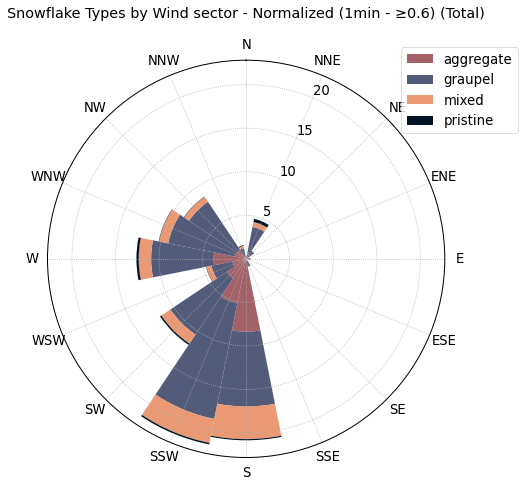

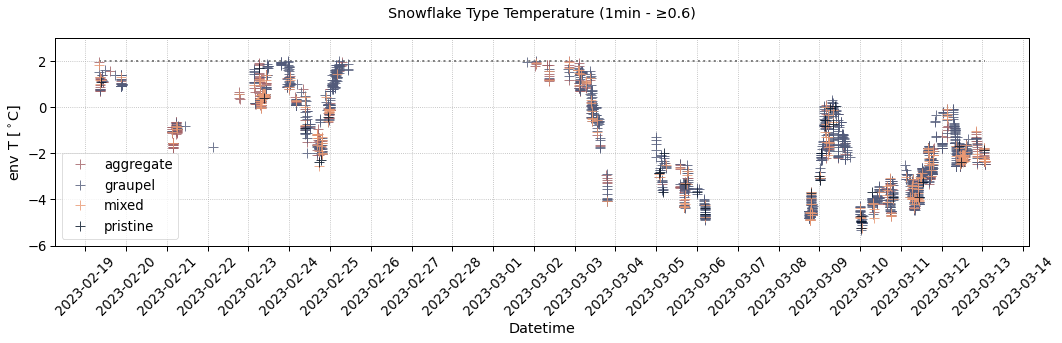

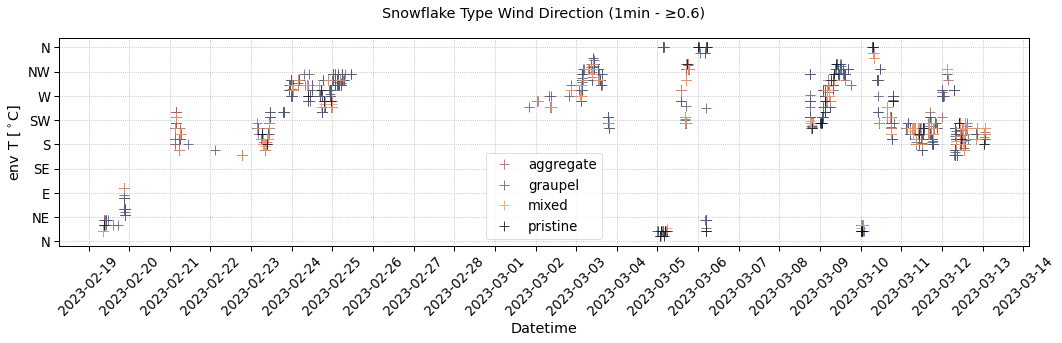

In [57]:

for freq in [#None, 
              '1min', #'10min', '30min'
             ]:
    for thresh in [#None, #0.2, 0.5, 
        0.6, #0.7
                   ]:
        df_env[f"{freq}_{thresh}"] = fct.test_dominance_threshold(df_t_thresh, frequency=freq, dominant_frac_threshold=thresh, fig_dir=FIG_DIR+'t_2degC/')# =FIG_DIR)
        dataset = (df_env[f"{freq}_{thresh}"].rename_axis('time')).to_xarray()
        dataset['env_T_test'] = dataset['env_T_test'].assign_attrs(units='degree_c', long_name='Air temperature')
        dataset['env_T_1h'] = dataset['env_T_1h'].assign_attrs(units='degree_c', long_name='1h Mean air temperature')
        dataset['env_DD_test'] = dataset['env_T_test'].assign_attrs(units='$^{\circ}$', long_name='Wind direction')
        dataset['env_FF_test'] = dataset['env_FF_test'].assign_attrs(units='m/s', long_name='Wind speed')
        
        dataset = dataset.assign_attrs(title = 'Snowfall habits processed with MASCDB',
                            institution='Dept. of Geoscience, University of Oslo',
                            contact_person='F. Hellmuth',
                            source='MASC',
                            location='Andenes',
                            history=f'Created with MASCDB. Time binning {freq}, threshold of minimum snowflake class {thresh}',
                            created_date=f'{formatted_utc_time} UTC',
                            reference='Grazioli, J., Ghiggi, G., Billault-Roux, AC. et al. MASCDB, a database of images, descriptors and microphysical properties of individual snowflakes in free fall. Sci Data 9, 186 (2022). https://doi.org/10.1038/s41597-022-01269-7')
        # dataset.to_netcdf(os.path.join(INPUT_DATA_DIR, f'MASC_DB/t_2degC/{campaign}_most_common_class_{freq}_{thresh}.nc'))


#### Rimed aggregate sensitivity test
include heavily rimed aggregates (≥ 80% riming) in graupel and recheck statistics.

In [ ]:
df_agg_riming = df_orig.copy()
mask_agg = df_agg_riming['snowflake_class_name'] == 'aggregate'
mask_riming = df_agg_riming['riming_deg_level'] >= 0.8
df_agg_riming.loc[mask_agg & mask_riming, 'snowflake_class_name'] = 'graupel'


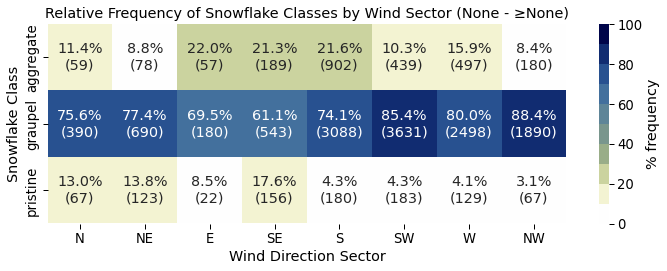

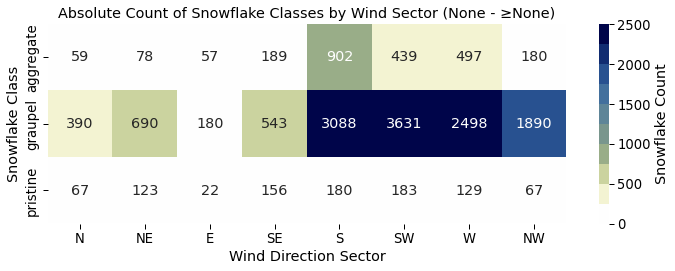

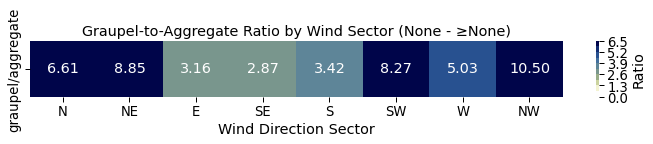

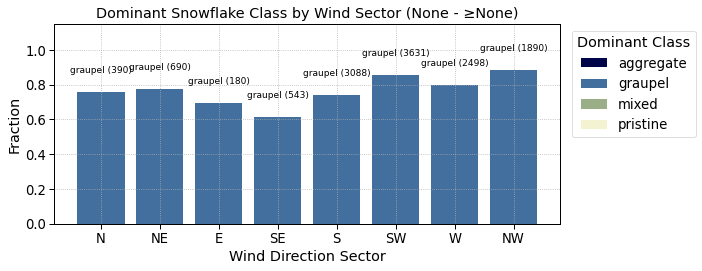

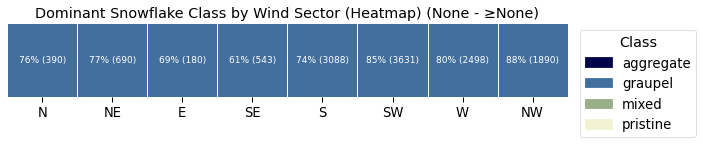

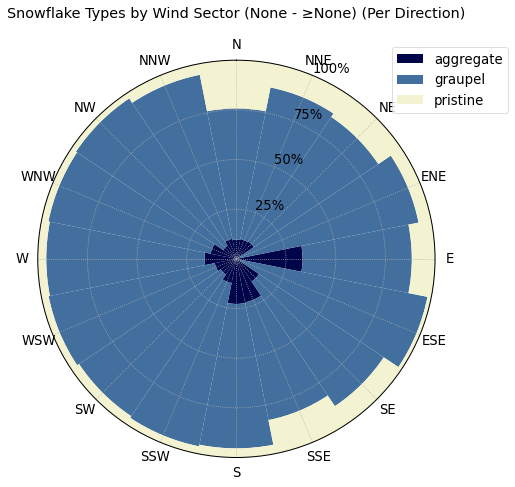

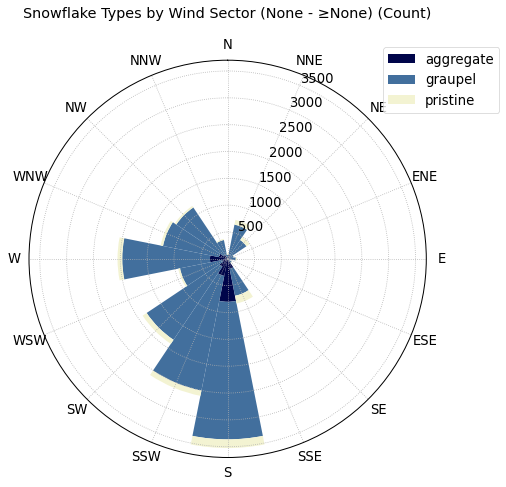

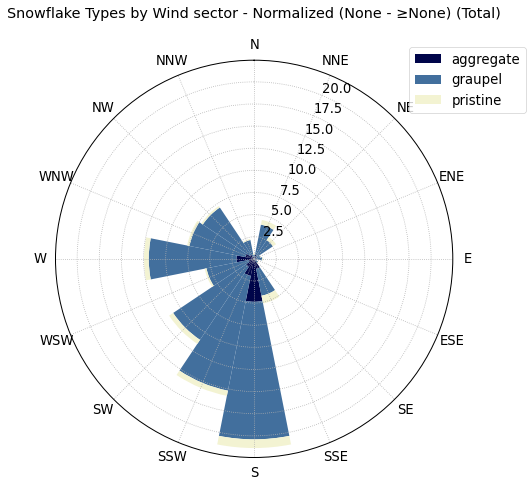

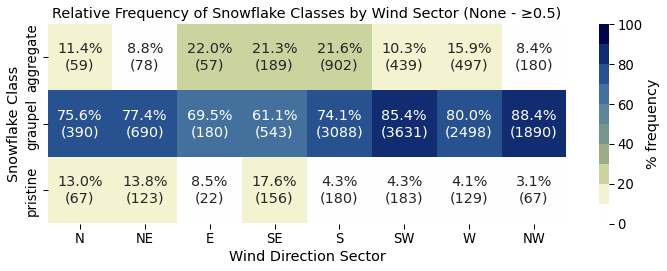

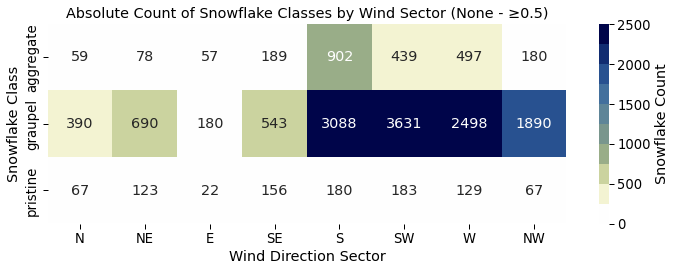

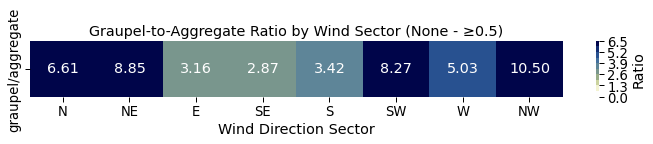

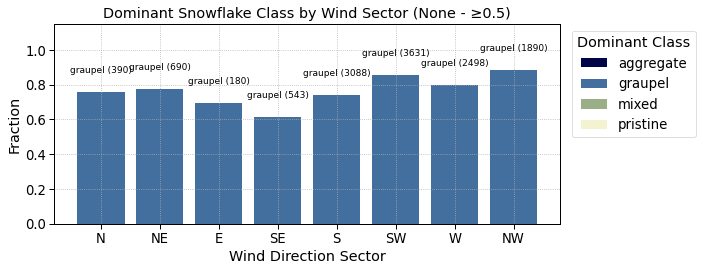

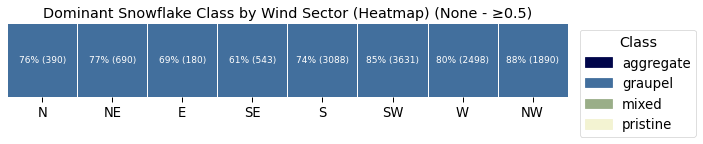

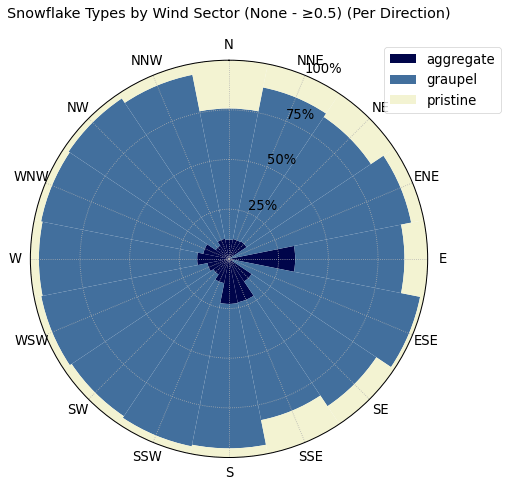

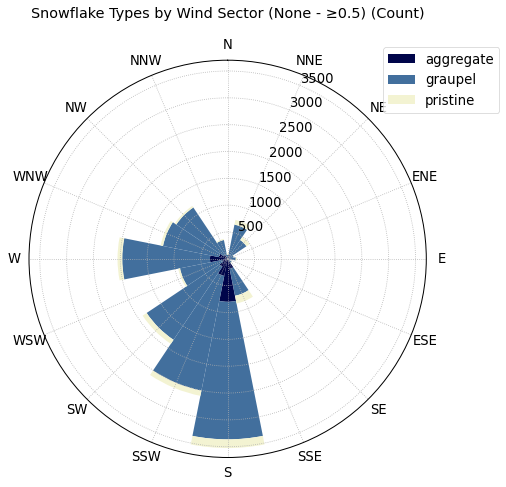

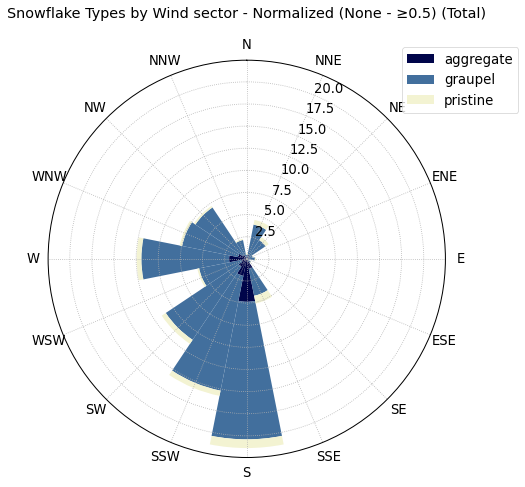

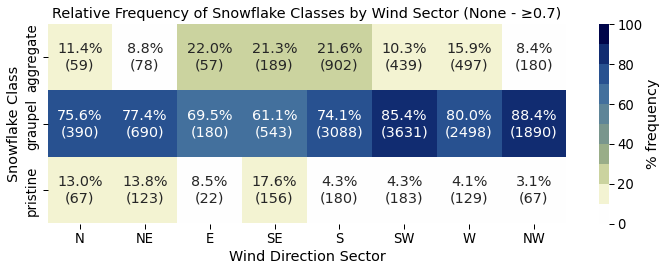

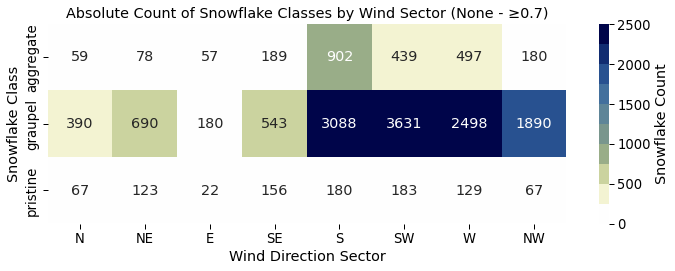

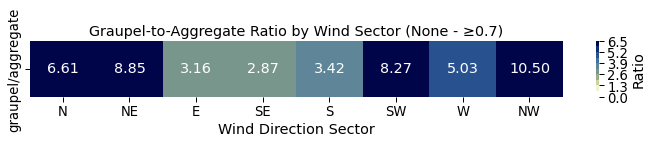

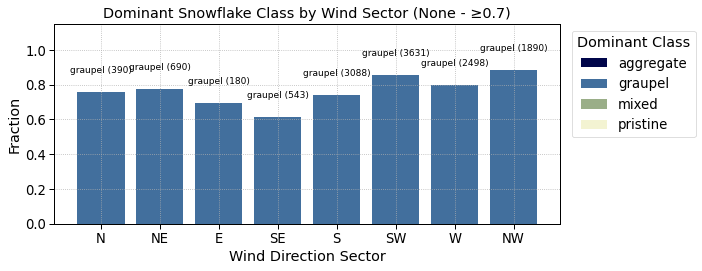

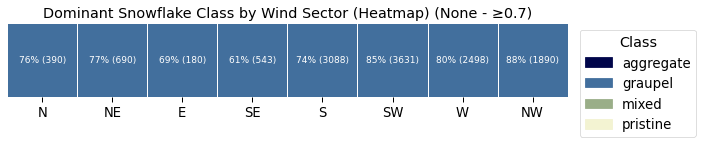

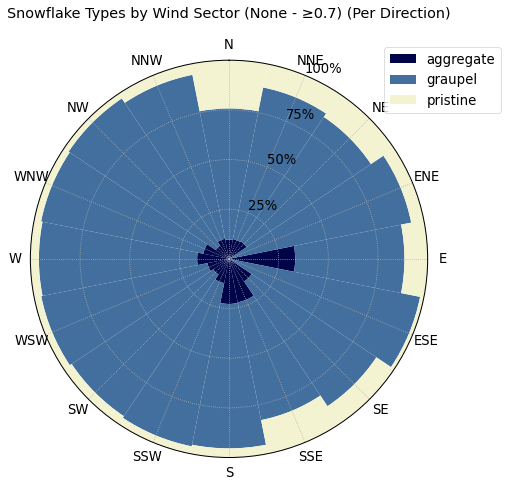

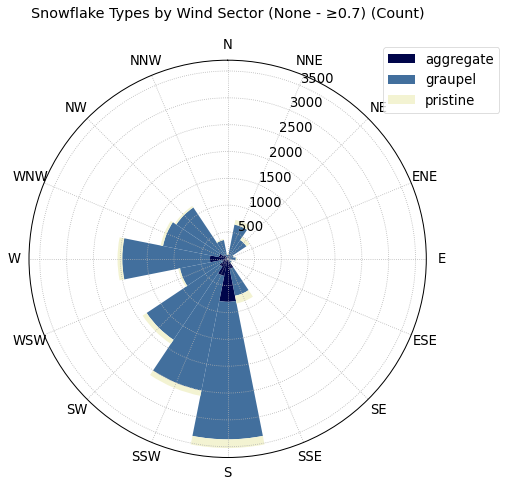

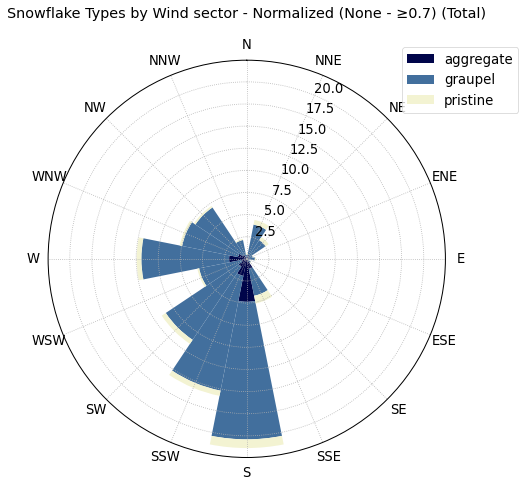

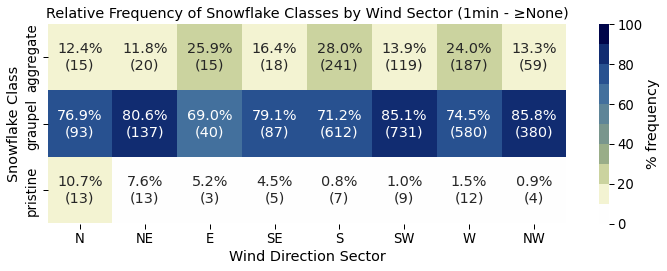

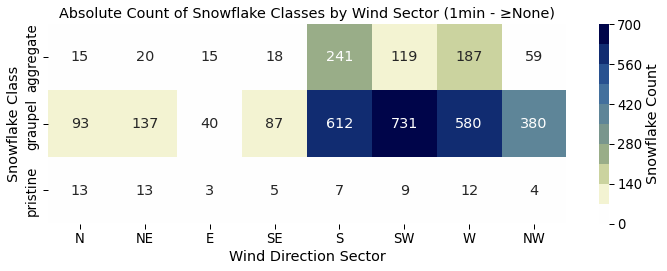

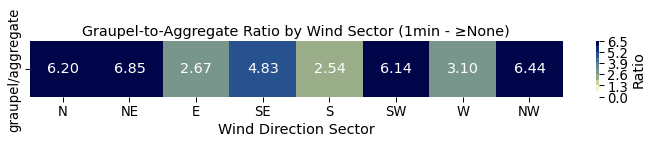

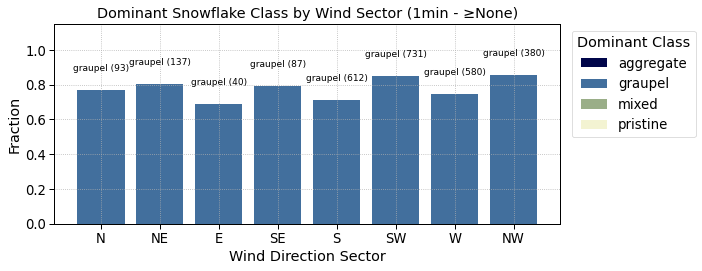

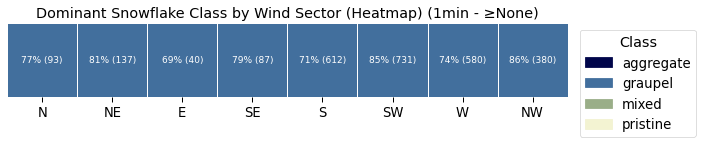

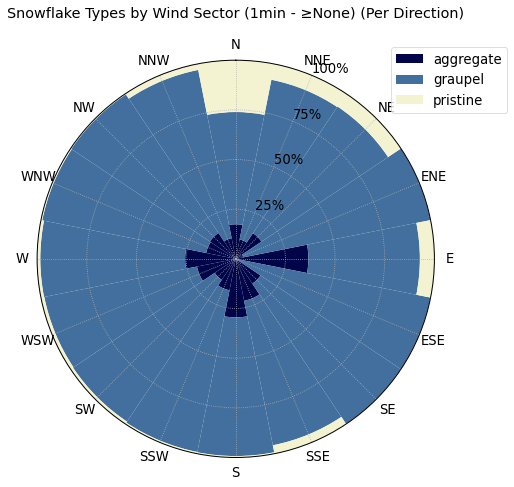

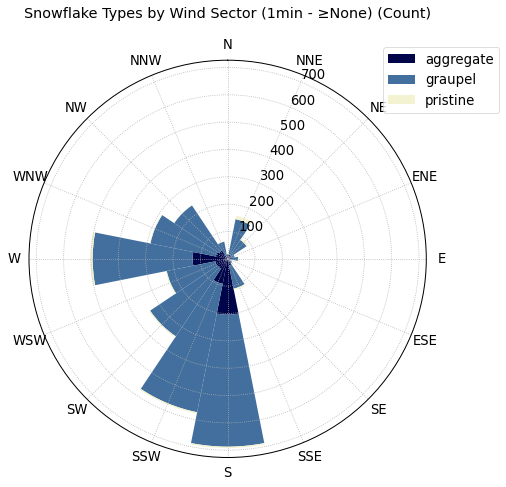

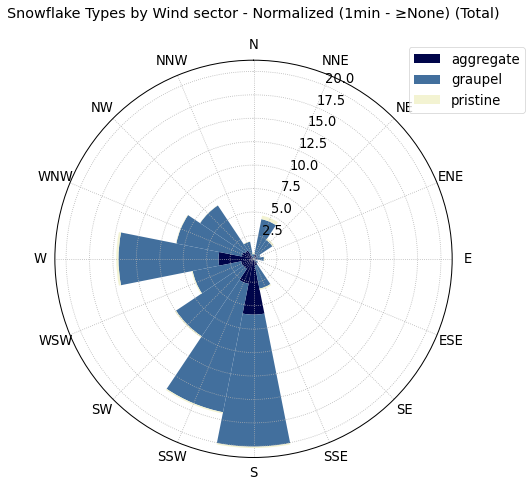

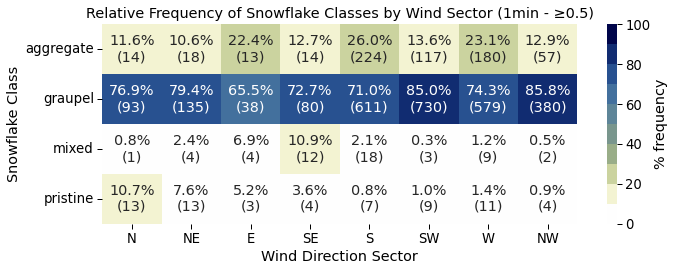

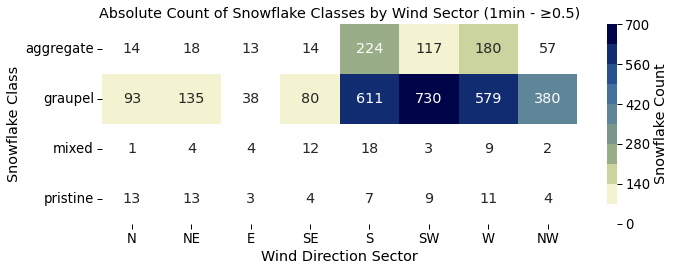

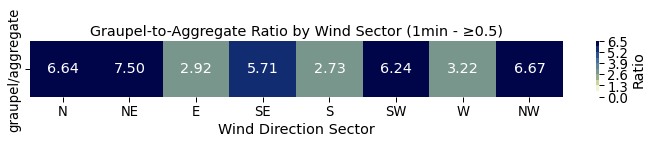

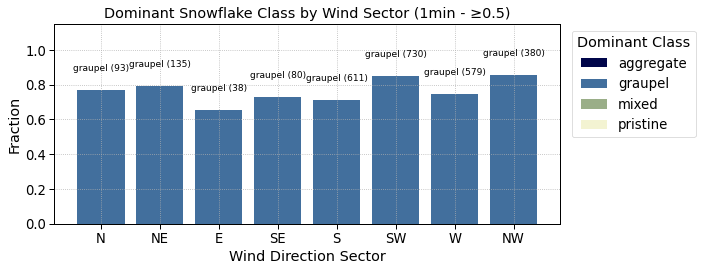

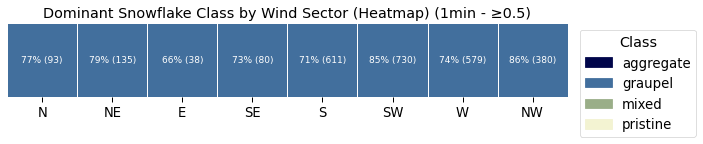

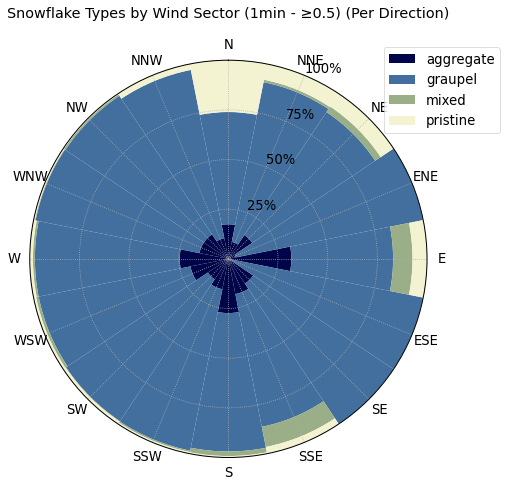

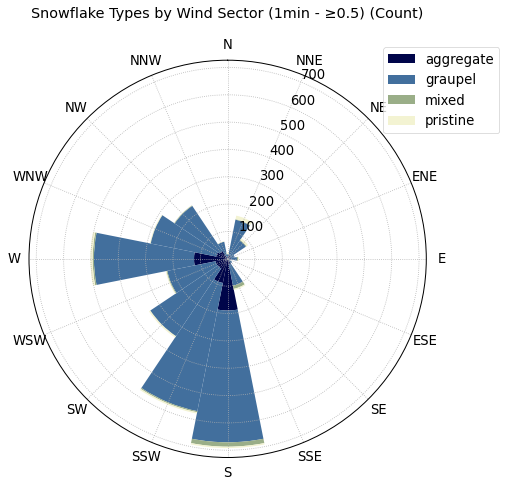

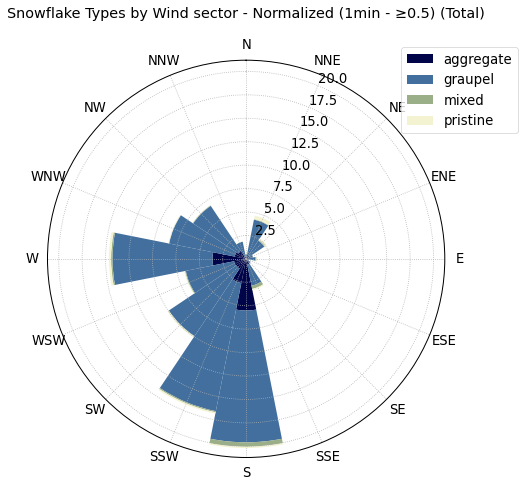

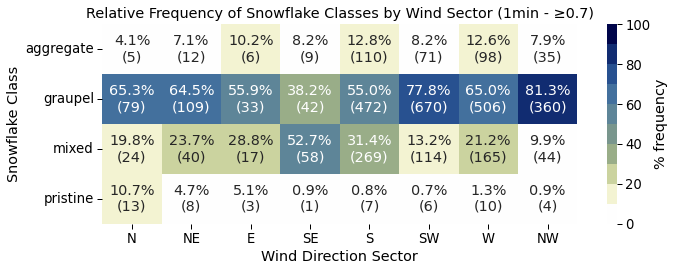

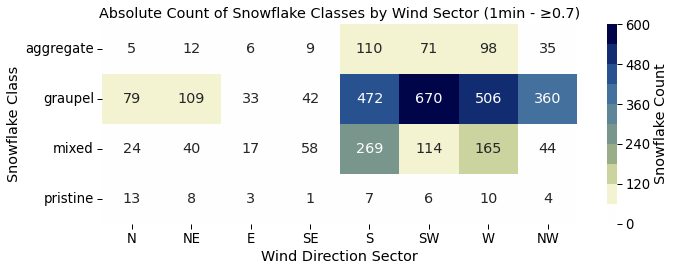

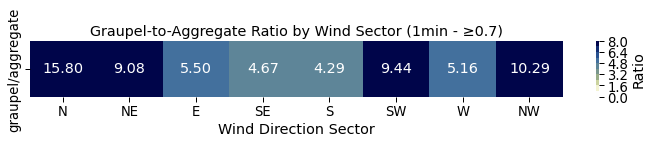

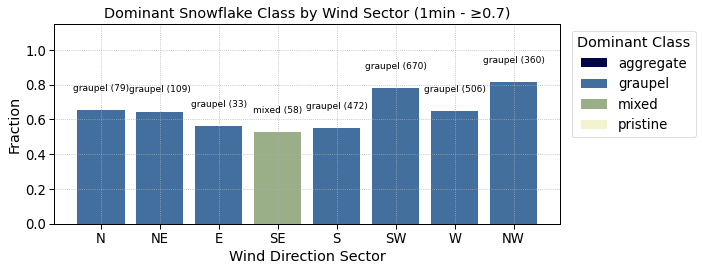

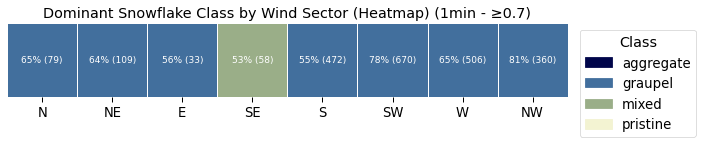

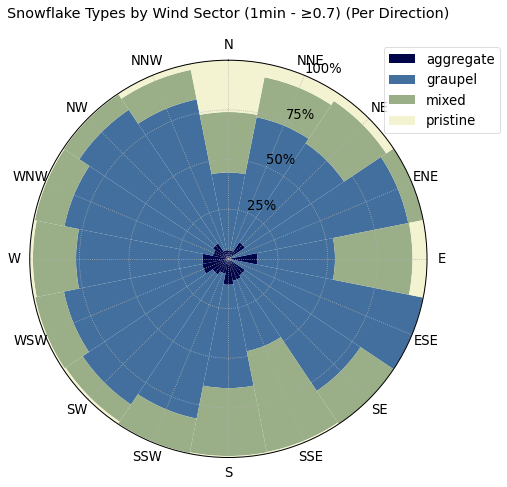

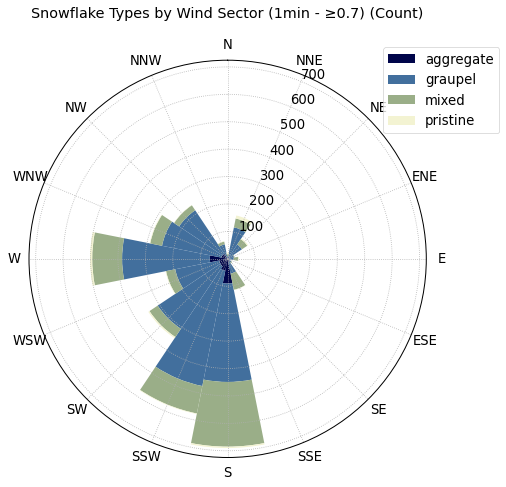

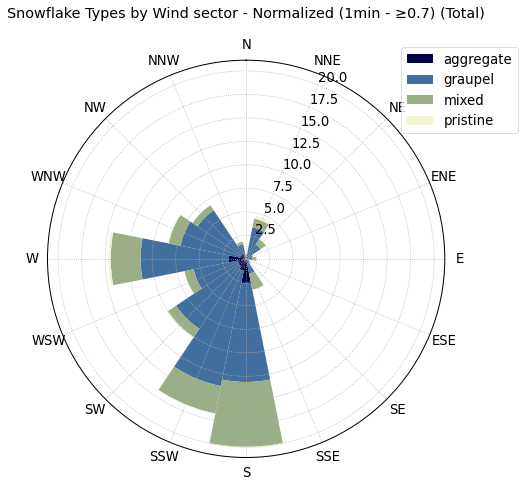

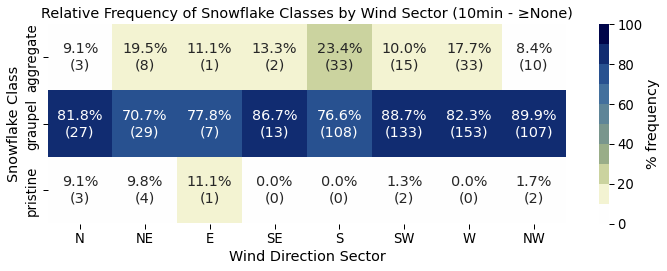

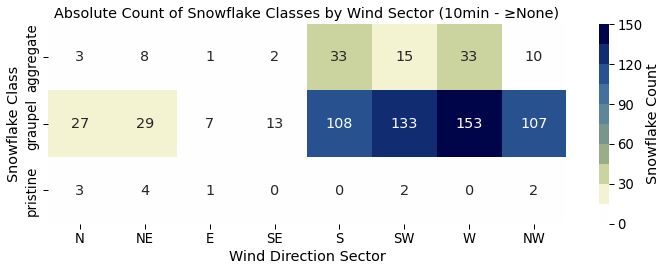

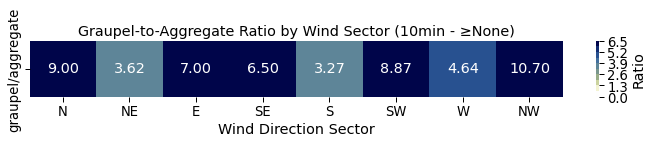

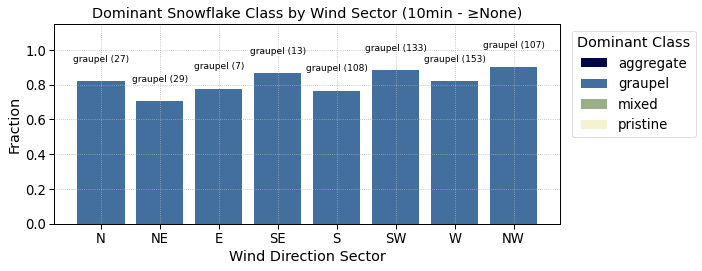

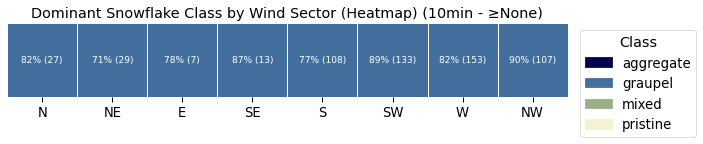

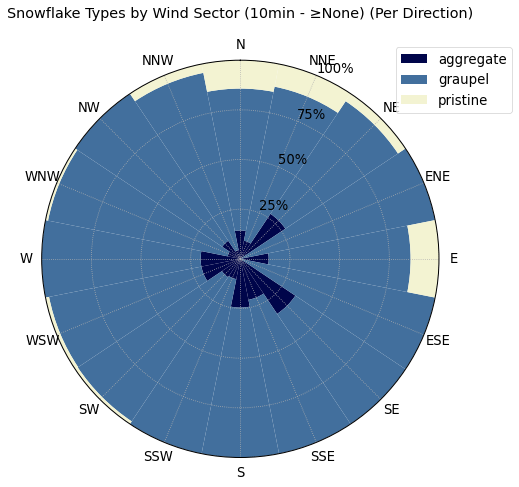

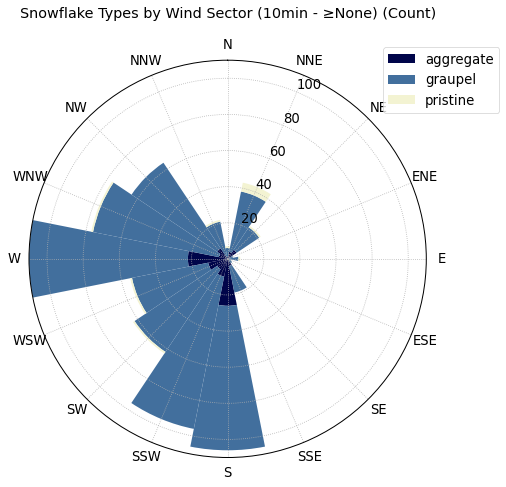

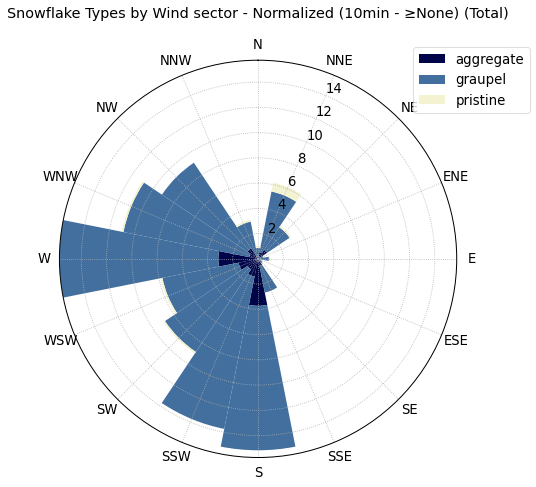

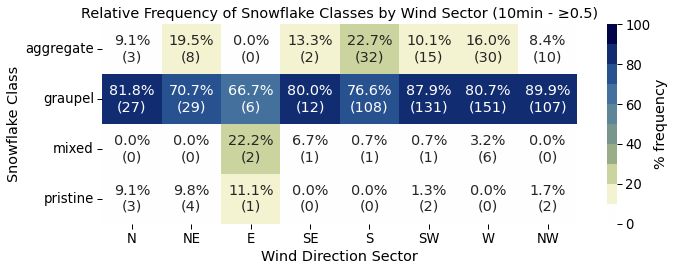

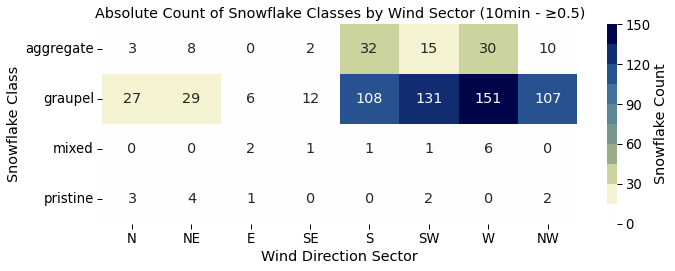

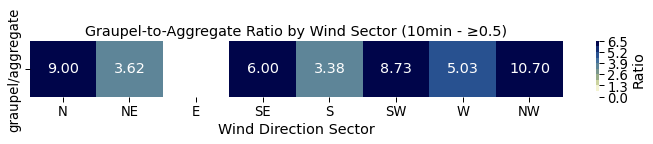

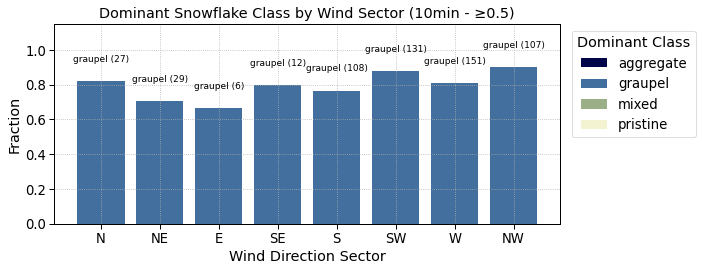

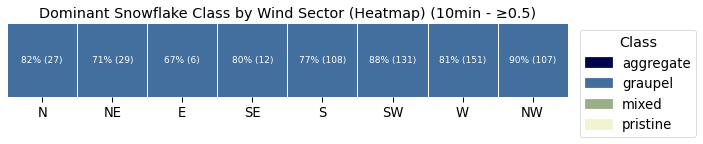

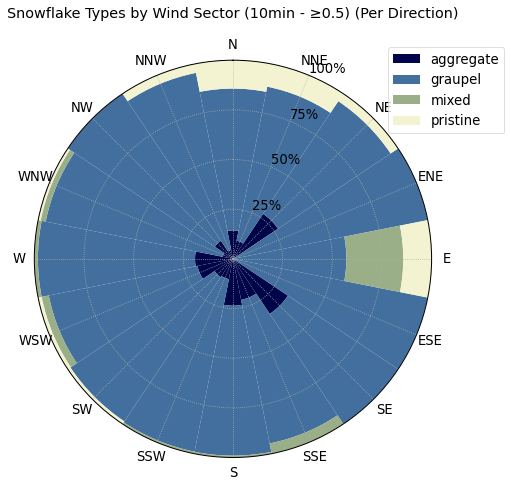

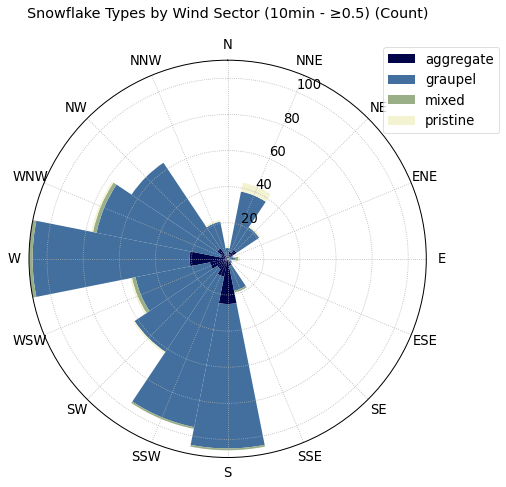

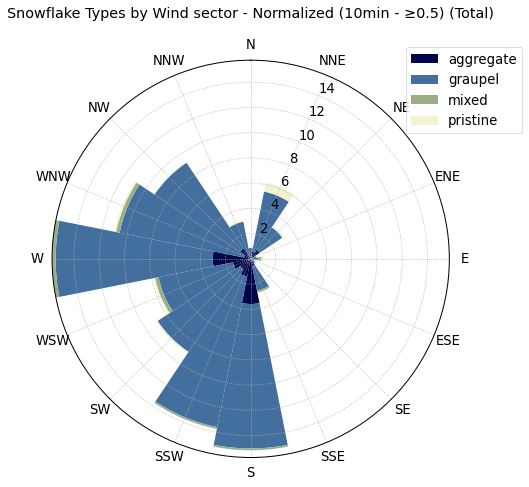

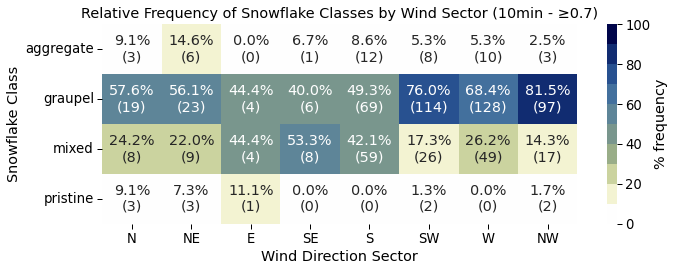

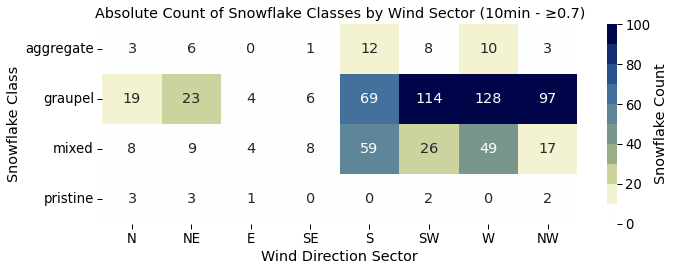

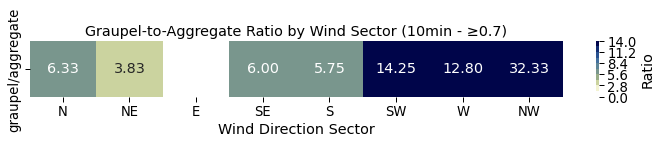

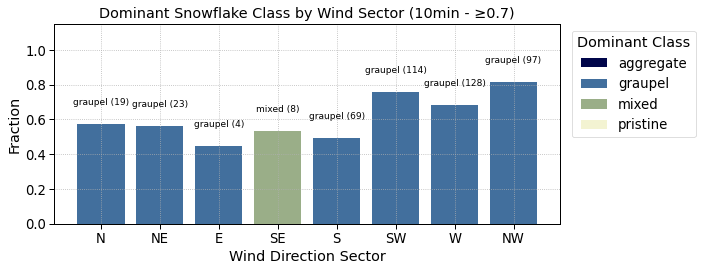

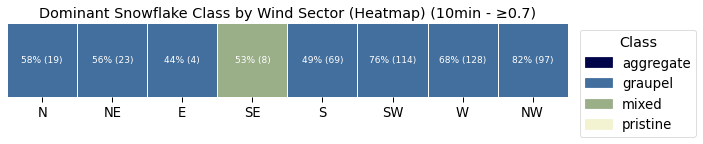

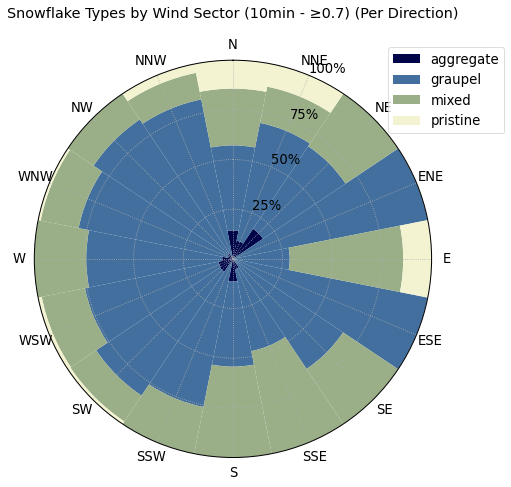

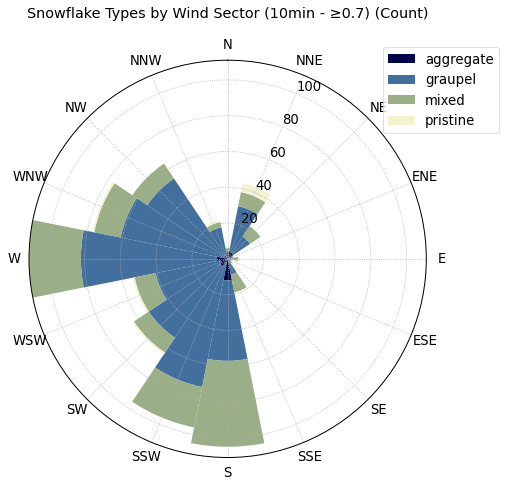

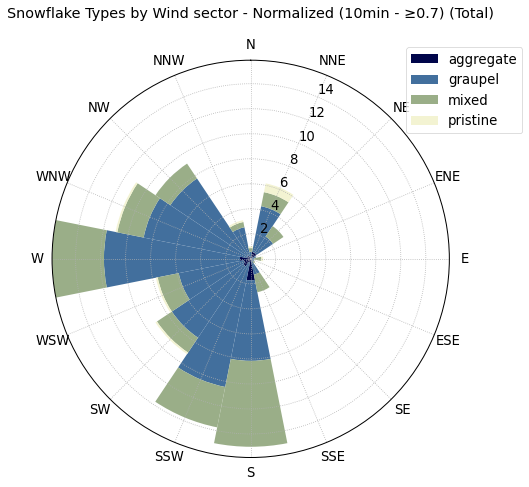

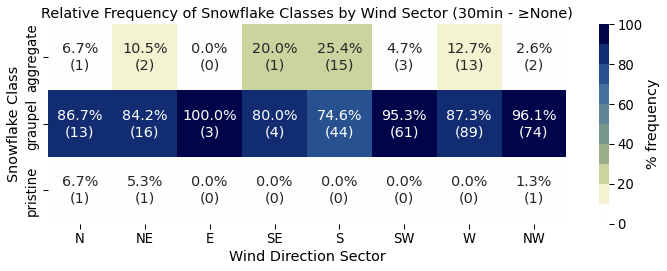

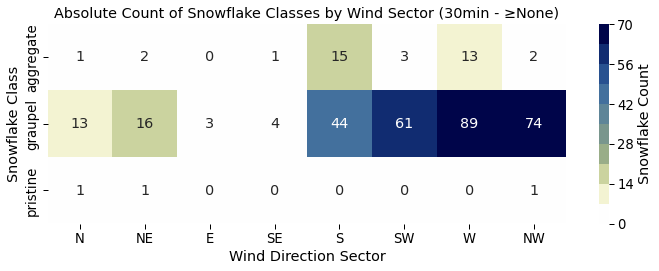

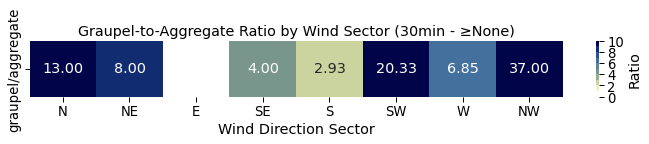

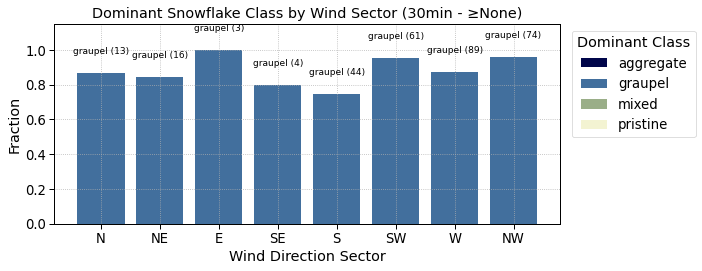

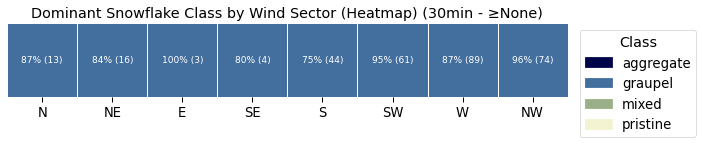

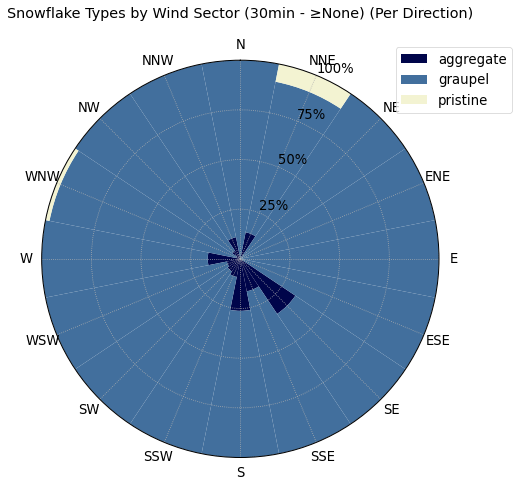

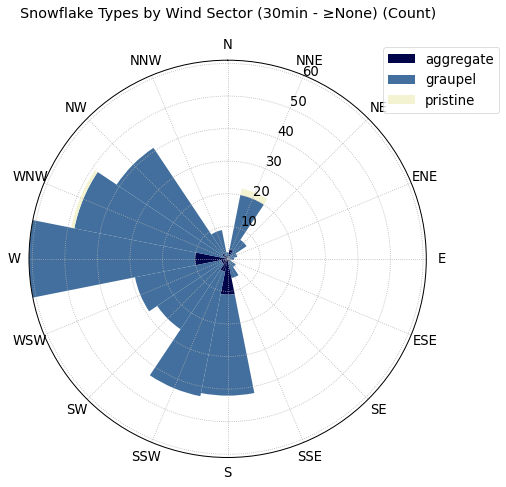

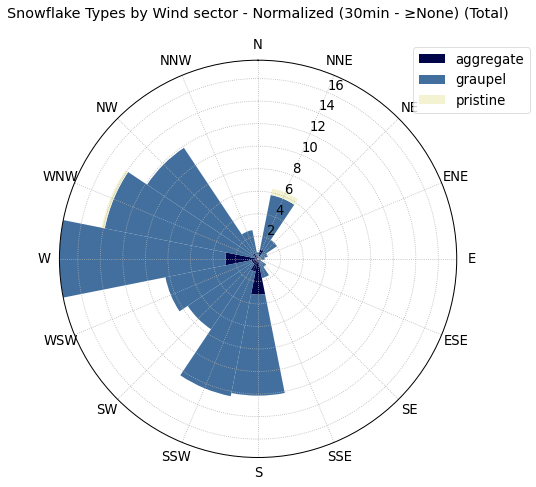

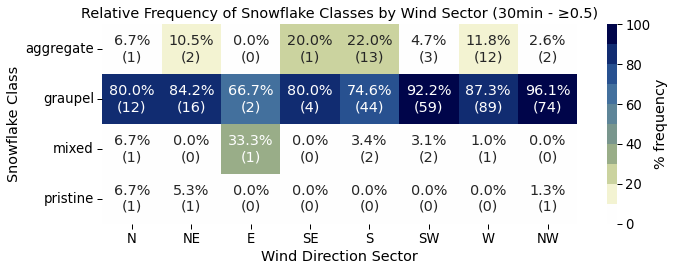

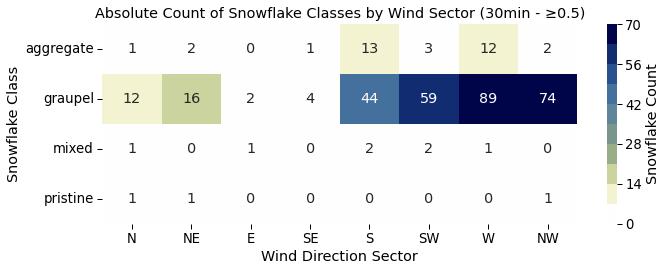

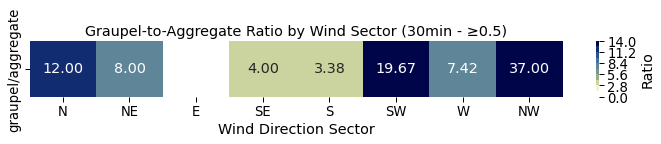

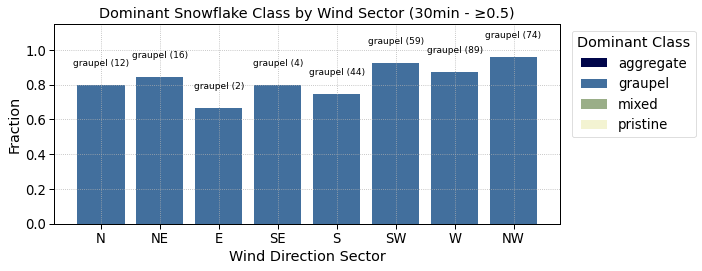

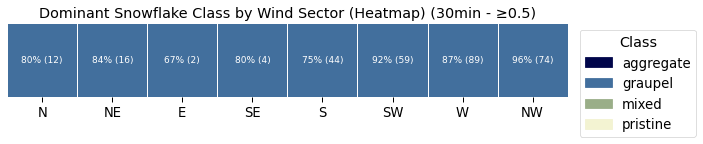

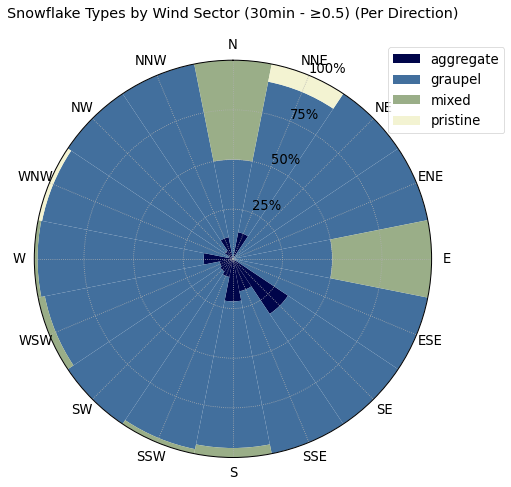

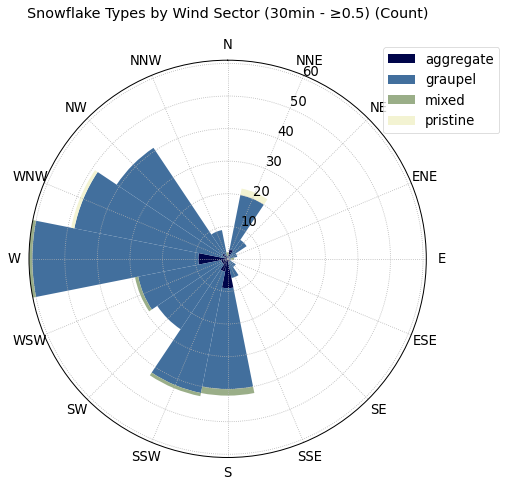

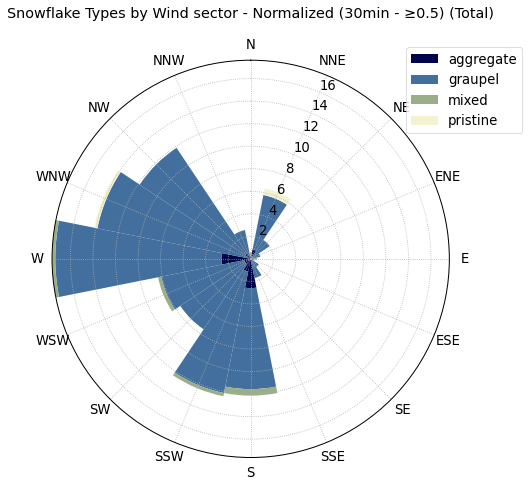

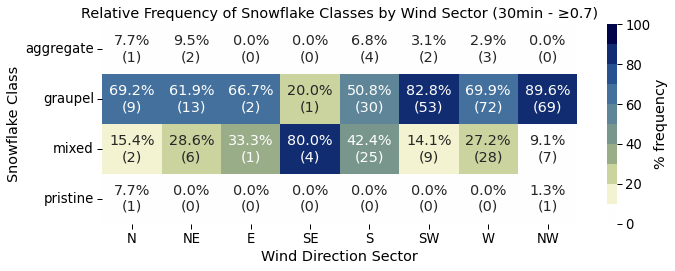

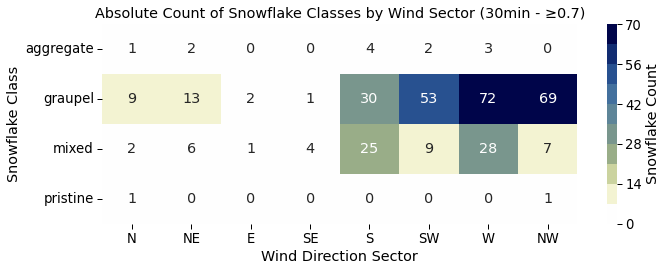

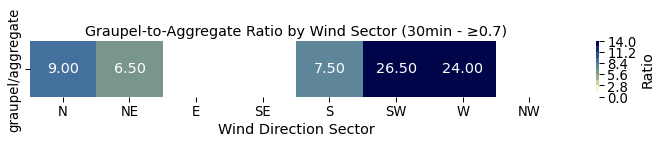

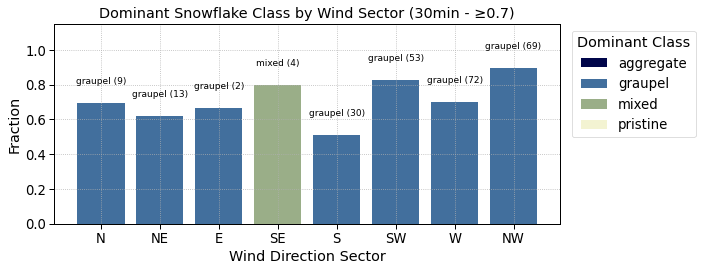

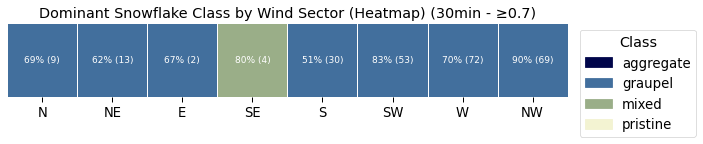

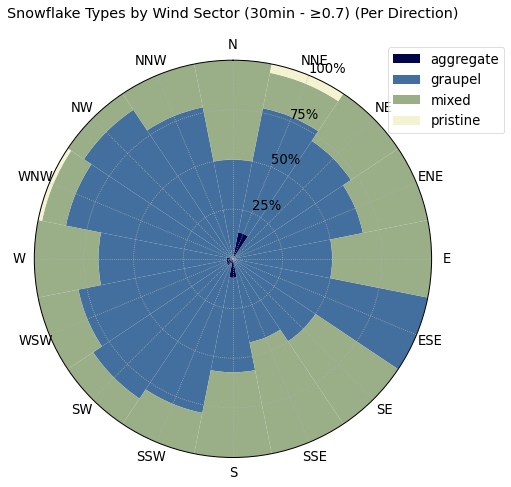

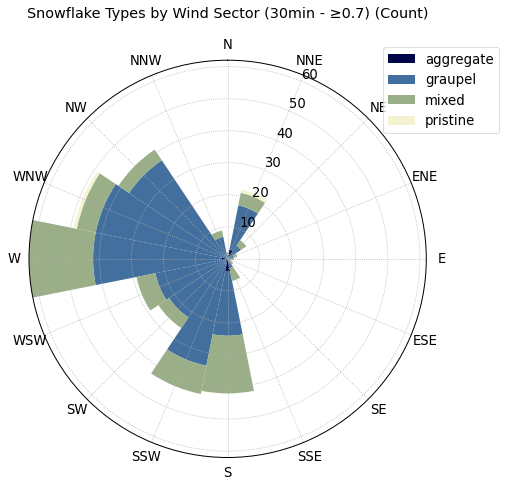

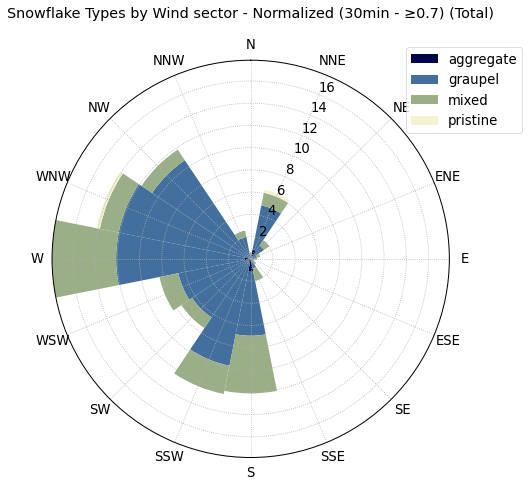

In [ ]:
df_env_riming = dict()

for freq in [None, #'1min', '10min', '30min'
             ]:
    for thresh in [None, #0.5, 0.7
                   ]:
        df_env_riming[f"{freq}_{thresh}"] = fct.test_dominance_threshold(df_agg_riming, frequency=freq, dominant_frac_threshold=thresh, fig_dir =FIG_DIR+'riming/')
        
        dataset = (df_env[f"{freq}_{thresh}"].rename_axis('time')).to_xarray()#
        dataset = dataset.assign_attrs(title = 'Snowfall habits processed with MASCDB',
                            institution='Dept. of Geoscience, University of Oslo',
                            contact_person='F. Hellmuth',
                            source='MASC',
                            location='Andenes',
                            history=f'Created with MASCDB. Time binning {freq}, threshold of minimum snowflake class {thresh}',
                            created_date=f'{formatted_utc_time} UTC',
                            reference='Grazioli, J., Ghiggi, G., Billault-Roux, AC. et al. MASCDB, a database of images, descriptors and microphysical properties of individual snowflakes in free fall. Sci Data 9, 186 (2022). https://doi.org/10.1038/s41597-022-01269-7')
        # dataset.to_netcdf(os.path.join(INPUT_DATA_DIR, f'MASC_DB/{campaign}_most_common_class_{freq}_{thresh}_riming_0_8.nc'))

In [ ]:
# # Group into 5-minute bins and count particle types
# # Count occurrences of each class in 5-minute bins and create new dataframe with time every 5min and each snowflake class name
# counts = df.groupby([pd.Grouper(freq='1min'), 'snowflake_class_name']).size().unstack(fill_value=0)

# # Find the most frequent class per 1-minute bin
# most_common_class = counts.idxmax(axis=1).rename('most_common_class')

# # merge this back into main DataFrame and annotate each row with the class dominant in its bin:
# # Re-bin the index so we can join
# df['1min_bin'] = df.index.floor('1min')
# # Map most_common_class back to each row
# df = df.merge(most_common_class, left_on='1min_bin', right_index=True)

# # # create dataframe with 1 min bins and most common class
# most_common_class_df = most_common_class.to_frame()
# new_df = pd.merge(counts, most_common_class_df,left_index=True , right_index=True)
# # new_df.to_xarray().to_netcdf(os.path.join(INPUT_DATA_DIR,f'MASC_DB/{campaign}_most_common_class_1min.nc'))

In [ ]:
df = campaign23.triplet
# Set the 'datetime' column as the index and the current index becomes a column
df.set_index('datetime', inplace=True)
df.index = df.index.rename('time')

# Convert the pandas DataFrame to xarray Dataset
ds = xr.Dataset.from_dataframe(df)

# Save to a NetCDF file
# ds.to_netcdf(os.path.join(INPUT_DATA_DIR,f'MASC_DB/{campaign}.nc'))

In [ ]:
# filtered = ds2.where(ds2['snowflake_class_name'] == 'graupel', drop=True)

In [ ]:
snowflake_class['graupel']

In [ ]:
graupel_largeD = graupel.arrange('cam1.Dmax', decreasing=True)
graupel_largeD.plot_triplets(n_triplets = 3)

In [ ]:
agg_largeD = agg.arrange('cam1.Dmax', decreasing=True)
agg_largeD.plot_triplets(n_triplets = 3)

In [ ]:
small_largeD = small.arrange('cam1.Dmax', decreasing=True)
small_largeD.plot_triplets(n_triplets = 3,zoom=True)

In [ ]:
### Dmax analysis  
# Retrieve event leading to largest Dmax 
graupel.arrange('cam1.Dmax', decreasing=True)  
largest_Dmax_event_id = graupel.arrange('cam1.Dmax', decreasing=True).cam1['event_id'].iloc[0]
idx_largest_Dmax_event = graupel.cam1['event_id'] == largest_Dmax_event_id
graupel_event = graupel.isel(idx_largest_Dmax_event).arrange('triplet.datetime', decreasing=False)
 
# graupel_event.cam1.sns.scatterplot(x="datetime", y="Dmax")
# graupel_event.full_db.sns.scatterplot(x="datetime", y="env_T")
graupel_event.full_db.sns.scatterplot(x="datetime", y="Dmax", hue="env_T")

In [ ]:
### Dmax analysis  
# Retrieve event leading to largest Dmax 
agg.arrange('cam1.Dmax', decreasing=True)  
largest_Dmax_event_id = agg.arrange('cam1.Dmax', decreasing=True).cam1['event_id'].iloc[0]
idx_largest_Dmax_event = agg.cam1['event_id'] == largest_Dmax_event_id
agg_event = agg.isel(idx_largest_Dmax_event).arrange('triplet.datetime', decreasing=False)
 
agg_event.cam1.sns.scatterplot(x="datetime", y="Dmax")
# agg_event.full_db.sns.scatterplot(x="datetime", y="env_T")
# agg_event.full_db.sns.scatterplot(x="datetime", y="Dmax", hue="env_T")

In [ ]:
# campaign23.select_snowflake_class('aggregate').triplet['snowflake_class_name']
# df0 = campaign23.cam0.drop(columns='flake_id',).reset_index()
# df1 = campaign23.cam1.drop(columns='flake_id',).reset_index()
# df2 = campaign23.cam2.drop(columns='flake_id',).reset_index()
# df3 = campaign23.triplet.drop(columns='flake_id',).reset_index()
# df0_agg = df0[df0['snowflake_class_name'] == 'aggregate']

# df1_agg = df1[df1['snowflake_class_name'] == 'aggregate']

# df2_agg = df2[df2['snowflake_class_name'] == 'aggregate']
# common = pd.merge(df1_agg, df2_agg,on='flake_id', )
# # common
# triplet = pd.merge(df3, common,on='flake_id', )
# triplet